# 6.3 word2vec及自定义分类器

In [1]:
import io, os, random, operator, sys
from collections import Counter
import random
import collections
import math
import sys

import re
import numpy as np
from tqdm import tqdm
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import pandas as pd

## 一些功能函数
需要阅读这些函数来对实验中用到的数据结构，步骤有一些理解

In [2]:
def dotProduct(d1, d2):
    """
    @param dict d1: a feature vector represented by a mapping from a feature (string) to a weight (float).
    @param dict d2: same as d1
    @return float: the dot product between d1 and d2
    """
    if len(d1) < len(d2):
        return dotProduct(d2, d1)
    else:
        return sum(d1.get(f, 0) * v for f, v in d2.items())


In [3]:
def increment(d1, scale, d2):
    """
    Implements d1 += scale * d2 for sparse vectors.
    @param dict d1: the feature vector which is mutated.
    @param float scale
    @param dict d2: a feature vector.
    """
    for f, v in d2.items():
        d1[f] = d1.get(f, 0) + v * scale


In [4]:
def pre_data(x):
    '''
    处理“ISO 8859-1” 的控制字符（0x80-0x9F）和文字符号（0xA0-0xFF）。
    '''
    x = re.sub(r'[\u00BD]+', r'one half', x)    #  换为one half

    x = re.sub(r'[\u00C8-\u00CB]+', r'E', x)    #  换为E
    x = re.sub(r'[\u00D9-\u00DC]+', r'U', x)    #  换为U

    x = re.sub(r'[\u00E0-\u00E5]+', r'a', x)    #  换为a
    x = re.sub(r'[\u00E6]+', r'ae', x)          #  换为ae
    x = re.sub(r'[\u00E7]+', r'c', x)           #  换为e
    x = re.sub(r'[\u00E8-\u00EB]+', r'e', x)    #  换为e
    x = re.sub(r'[\u00EC-\u00EF]+', r'i', x)    #  换为i
    x = re.sub(r'[\u00F0]+', r'eth', x)         #  换为eth
    x = re.sub(r'[\u00F1]+', r'n', x)           #  换为n
    x = re.sub(r'[\u00F2-\u00F6]+', r'o', x)    #  换为o
    x = re.sub(r'[\u00F9-\u00FC]+', r'u', x)    #  换为u
    x = re.sub(r"[\u0080-\u009F]+", r" ", x)    #  去除控制字符
    # x = re.sub(r"[^\u0080-\u009F\u00A0-\u00FF]+", r" ", x)  # ^\u0080-\u009F\u00A0-\u00FF
    return x.strip()


In [5]:
def readExamples(path):
    '''
    读取数据
    '''
    examples = []
    for line in open(path, encoding = "ISO-8859-1"):
        # Format of each line: <output label (+1 or -1)> <input sentence>
        y, x = line.split(' ', 1)
        examples.append((pre_data(x), int(y)))
    print('Read %d examples from %s' % (len(examples), path))
    return examples


In [6]:
def evaluatePredictor(examples, predictor):
    '''
    在|examples|上测试|predictor|的性能，返回错误率
    '''
    error = 0
    for x, y in examples:
        if predictor(x) != y:
            error += 1
    return 1.0 * error / len(examples)

## Feature extrator (Your codes here)

### （3） 使用word2vec作为特征
(a) 获得词向量。你可以借鉴第一次的作业，使用gensim来自己训练一个word2vec, 或者加载预训练过的word2vec(gensim的网站上有说明如何下载并使用预训练过的词向量)。
(b) 考虑如何使用词向量得到句子的表示向量（feature）。
(c) 将向量转化为其余部分可以处理的形式（如：dict）
(d) 考虑如何**更好地**使用词向量得到句子的表示向量（feature）。

提示: 在ipynb的代码块中可以使用! 来执行命令行中的命令, 例如
```
!pip install gensim
```

In [7]:
# 使用预训练的word2vec模型(FastText Word Embeddings)加载词向量 
def load_vectors():
    fin = io.open('./data/wiki-news-300d-1M.vec', 'r', encoding='utf-8', newline='\n', errors='ignore')
    n, d = map(int, fin.readline().split())
    data_w2v = {}
    i = 0
    for line in fin:
        tokens = line.rstrip().split(' ')
        data_w2v[tokens[0]] = list(map(float, tokens[1:]))
    return data_w2v

In [8]:
data_w2v = load_vectors()

In [9]:
def extractFeatures(x):
    """
    从字符串x中提取特征
    @param string x: 
    @return vector: feature vector representation of x.
    """
    # 将句子x拆分成单个字符或单词
    tokens = x.split()
    # 句子的词向量表示
    vectors = [data_w2v[token] for token in tokens if token in data_w2v.keys()]
    # 将句子中的每个单词转换为对应的词向量，然后将这些词向量的平均值作为该句子的特征向量
    vectors = np.mean(vectors, axis=0)
    return vectors

### (4) Test your feature extractor
实现了特征提取函数之后，可以简单地测试输出的正确性

In [10]:
extractFeatures("a truly wonderful wonderful wonderfultale combined with stunning animation .")

array([-2.08777778e-02, -2.64444444e-02, -4.95222222e-02, -1.36555556e-02,
        6.24444444e-03, -6.72555556e-02, -2.45555556e-02,  2.43888889e-02,
       -1.15888889e-02,  9.53333333e-03,  2.77777778e-04, -3.13888889e-02,
       -5.75111111e-02, -4.70888889e-02,  5.36555556e-02, -1.72222222e-03,
        3.63777778e-02, -5.08888889e-02, -7.00888889e-02, -2.40666667e-02,
       -4.45444444e-02,  2.93444444e-02,  3.75777778e-02,  6.72666667e-02,
        3.62222222e-03, -5.29000000e-02,  6.70000000e-03, -4.35000000e-02,
        1.88444444e-02, -1.63111111e-02, -2.12555556e-02, -2.38777778e-02,
        4.44444444e-02, -3.00777778e-02,  6.78222222e-02,  7.83333333e-03,
        9.55555556e-04,  2.03333333e-03,  4.44333333e-02,  2.03111111e-02,
        6.28111111e-02, -1.41222222e-02,  4.06555556e-02, -5.61111111e-02,
       -2.76444444e-02, -2.38333333e-02,  3.49333333e-02, -1.76222222e-02,
       -6.21666667e-02, -1.27222222e-02, -4.04888889e-02, -7.68888889e-03,
       -6.53544444e-01,  

## 学习与梯度更新
你需要理解题目中的loss_function, 自行推导出weights的更新公式，
通过对训练集上样本的迭代，来更新weights

In [11]:

def learnPredictor(trainExamples, validateExamples, featureExtractor, epochs, eta, use_momentum, momentum=0.9):
    '''
    给定训练数据和测试数据，特征提取器|featureExtractor|、训练轮数|numIters|和学习率|eta|，
    返回学习后的权重weights
    你需要实现随机梯度下降优化权重
    '''
    
    # 返回每次迭代的权重、Loss、训练集和验证集的错误率
    weights, weight_epochs = np.zeros(300), []
    losses_train, losses_val = [], []
    errors_train, errors_val =  [], []
    #动量
    velocity = 0

    for  i in range(0, epochs):        
        with tqdm(total=len(trainExamples), desc=f"[Epoch {(i+1):3d}/{epochs}]") as pbar:
            #本次迭代的Loss
            loss_batch = []
            for j,(x,y) in enumerate(trainExamples):
                # 每10次迭代下降一半的学习率
                if i > 0 and i % 10 == 0:
                    eta *=0.5
                x = featureExtractor(x)
                # 计算预测值
                pred = np.dot(weights, x)
                # 计算梯度
                margin = y * pred
                if margin < 1: 
                    if use_momentum:
                        grad = -y * x
                        velocity = velocity * momentum - eta *grad
                        weights += velocity
                    else:
                        # increment(weights, eta * y, features)
                        grad = -y * x
                        weights -= eta * grad
                       
                # 计算训练损失函数
                loss = max(0, 1 - margin)
                loss_batch.append(loss)

                # 打印loss
                if j > 0 and j % 100 == 0:
                    pbar.set_postfix({'Train Loss': '{:4f}'.format(np.mean(loss_batch))})
                    pbar.update(100)
                elif j == len(trainExamples)-1:
                    pbar.set_postfix({'Train Loss': '{:4f}'.format(np.mean(loss_batch))})
                    pbar.update(j % 100+1)
                    

            # 计算验证集损失函数
            valLoss = sum(max(0, 1 - np.dot(weights,featureExtractor(x))*y) for x, y in validateExamples)/len(validateExamples)
            
            # 计算训练集和验证集的错误率
            trainError = evaluatePredictor(trainExamples, lambda x : (1 if np.dot(featureExtractor(x), weights) >= 0 else -1))
            valError= evaluatePredictor(validateExamples, lambda x : (1 if np.dot(featureExtractor(x), weights) >= 0 else -1))
            loss_batch = np.mean(loss_batch)
            pbar.set_postfix({'Loss(train|val)': '{:4f}|{:4f}'.format(loss_batch, valLoss), 
                              'Error rate(train|val)': '{:4f}|{:4f}'.format(trainError,valError)})

            #记录每次迭代后的Loss、权重和错误率
            weight_epochs.append(weights)
            losses_train.append(loss_batch)
            losses_val.append(valLoss)
            errors_train.append(trainError)
            errors_val.append(valError)
    return weight_epochs, losses_train, losses_val, errors_train, errors_val


## 已经定义好的训练测试流程

### 训练模型

(a) 超参请自行更改 
(b) 自行增加代码来进行训练loss和测试loss变化图的绘制 
(b) 分析性能,模型泛化能力, 权重weights的可解释性等等 

In [12]:
trainExamples = readExamples('data/data_rt.train')
testExamples = readExamples('data/data_rt.test')

# 从源训练集和测试集中各取10%，组合当验证集
trainExamples, validateExamples = train_test_split(trainExamples, test_size=0.1, random_state=10)
testExamples, validateExamples1 = train_test_split(testExamples, test_size=0.1, random_state=10)
validateExamples.extend(validateExamples1)
# 打印训练集、验证集和测试集的样本大小
print('Dataset Size(training|validation|test)={}|{}|{}'.format(len(trainExamples), len(validateExamples), len(testExamples)))

featureExtractor = extractFeatures

Read 3554 examples from data/data_rt.train
Read 3554 examples from data/data_rt.test
Dataset Size(training|validation|test)=3198|712|3198


In [13]:
# 记录调参结果
exec_result = pd.DataFrame(columns=['model', 'epochs', 'eta', 'use_momentum', 'momentum', 
                                    'best_epoch', 'best_errors_val', 'best_weights', 
                                    'losses_train', 'losses_val', 'errors_train', 'errors_val'])
# 网格搜索

epochs = 12
for eta in [0.1, 0.05, 0.01, 0.005, 0.001, 0.0005]:
    for use_momentum in [True, False]:
        if use_momentum:
            for momentum in [0.1, 0.5, 0.9]:
                weight_epochs, losses_train, losses_val, errors_train, errors_val = learnPredictor(trainExamples, validateExamples, featureExtractor, 
                                                                    epochs=epochs, 
                                                                    eta=eta, 
                                                                    use_momentum=use_momentum, 
                                                                    momentum=momentum)  
                best_errors_val = min(errors_val) 
                print('eat={} use_momentum={} momentum={} errors_val={:4f}'.format(eta, use_momentum, momentum, best_errors_val),'\n') 
                best_epoch = errors_val.index(best_errors_val)
                best_weights = weight_epochs[best_epoch]
                exec_result.loc[exec_result.shape[0]] = ['word2vec', epochs, eta, use_momentum, momentum, 
                                                        best_epoch, best_errors_val, best_weights,
                                                        losses_train, losses_val, errors_train, errors_val]    
        else:
            weight_epochs, losses_train, losses_val, errors_train, errors_val = learnPredictor(trainExamples, validateExamples, featureExtractor, 
                                                                    epochs=epochs, 
                                                                    eta=eta, 
                                                                    use_momentum=use_momentum, 
                                                                    momentum=0)     
            print('eat={} use_momentum={} errors_val={:4f}'.format(eta, use_momentum, min(errors_val)),'\n')   
            best_errors_val = min(errors_val) 
            best_epoch = errors_val.index(best_errors_val)
            weights = weight_epochs[best_epoch]
            exec_result.loc[exec_result.shape[0]] = ['word2vec', epochs, eta, use_momentum, 0, 
                                                    best_epoch, best_errors_val, best_weights,
                                                    losses_train, losses_val, errors_train, errors_val]   
exec_result.to_csv('./output/exec_result_word2vec.csv', index=0)


[Epoch  12/12]: 100%|██████████| 3198/3198 [00:02<00:00, 1381.19it/s, Loss(train|val)=0.500842|0.539109, Error rate(train|val)=0.208881|0.217697]


eat=0.1 use_momentum=True momentum=0.1 errors_val=0.217697 



[Epoch  12/12]: 100%|██████████| 3198/3198 [00:02<00:00, 1347.03it/s, Loss(train|val)=0.485692|0.542591, Error rate(train|val)=0.205754|0.227528]


eat=0.1 use_momentum=True momentum=0.5 errors_val=0.221910 



[Epoch  12/12]: 100%|██████████| 3198/3198 [00:02<00:00, 1411.03it/s, Loss(train|val)=0.512501|0.588104, Error rate(train|val)=0.207004|0.238764]


...

eat=0.0005 use_momentum=True momentum=0.5 errors_val=0.469101 



[Epoch  12/12]: 100%|██████████| 3198/3198 [00:02<00:00, 1394.38it/s, Loss(train|val)=0.805184|0.803043, Error rate(train|val)=0.281426|0.275281]


eat=0.0005 use_momentum=True momentum=0.9 errors_val=0.275281 



[Epoch  12/12]: 100%|██████████| 3198/3198 [00:02<00:00, 1398.67it/s, Loss(train|val)=0.978766|0.976182, Error rate(train|val)=0.482176|0.469101]

eat=0.0005 use_momentum=False errors_val=0.469101 



### 结果整理

In [14]:
exec_result[['model', 'epochs', 'eta', 'use_momentum', 'momentum', 'best_epoch' ,'best_errors_val']]


,model,epochs,eta,use_momentum,momentum,best_epoch,best_errors_val
0,word2vec,12,0.1000,True,0.1,10,0.217697
1,word2vec,12,0.1000,True,0.5,4,0.221910
2,word2vec,12,0.1000,True,0.9,3,0.224719
3,word2vec,12,0.1000,False,0.0,8,0.221910
4,word2vec,12,0.0500,True,0.1,9,0.224719
5,word2vec,12,0.0500,True,0.5,7,0.220506
6,word2vec,12,0.0500,True,0.9,2,0.216292
7,word2vec,12,0.0500,False,0.0,9,0.226124
8,word2vec,12,0.0100,True,0.1,4,0.262640
9,word2vec,12,0.0100,True,0.5,10,0.242978


#### epoch对结果的影响

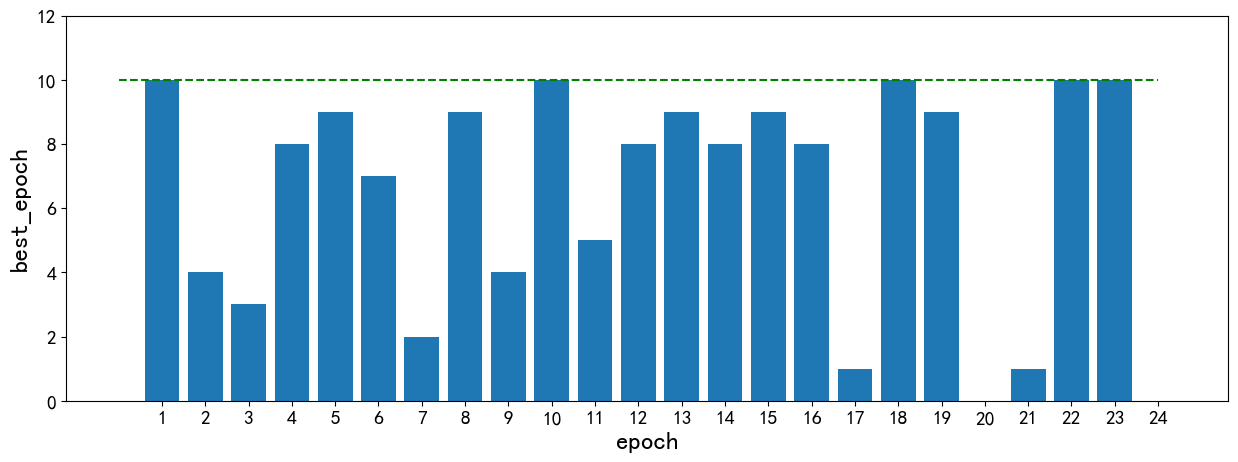

In [15]:
plt.figure(figsize=(15,5), dpi=100)
plt.rcParams['font.sans-serif']=['SimHei']
plt.bar(list(range(1,len(exec_result)+1)), exec_result['best_epoch'].values.tolist())
plt.plot([0,24],[10,10],c='g',ls='--')
plt.xlabel('epoch', fontsize=18, fontweight='bold')
plt.ylabel('best_epoch', fontsize=18, fontweight='bold')
plt.xticks(range(1,len(exec_result)+1), fontsize=14)
plt.yticks(range(0,13,2),fontsize=14)
plt.show()

#### 动量对结果的影响

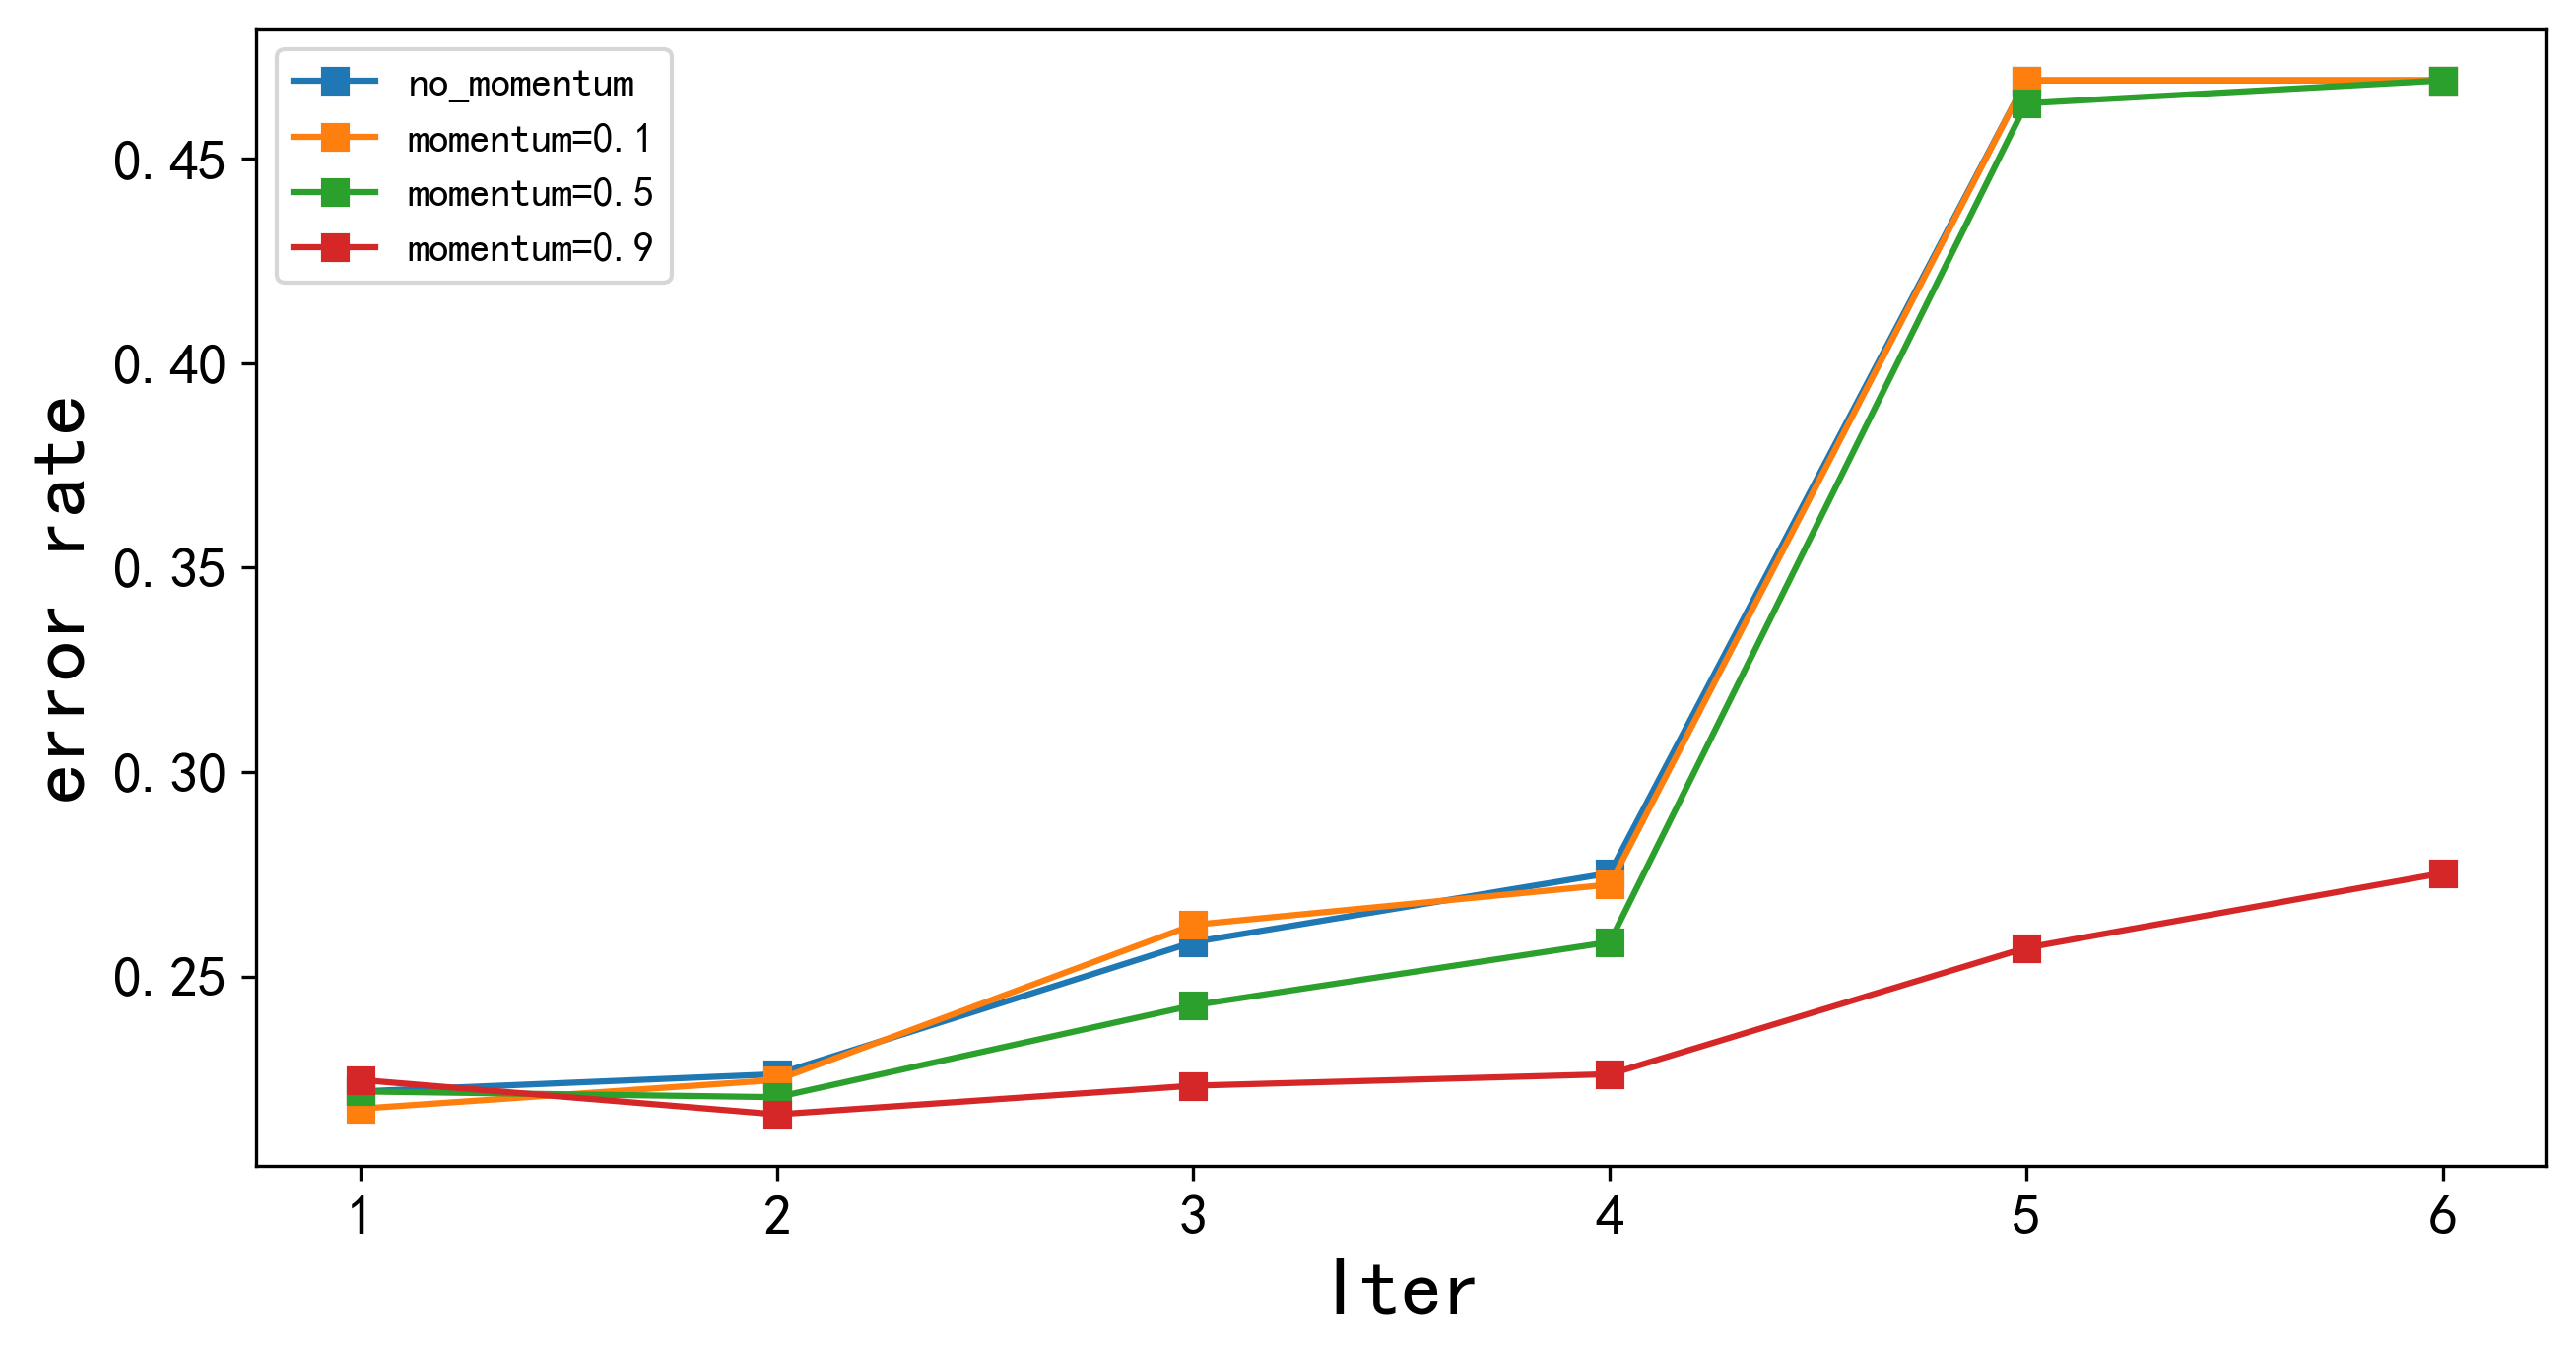

In [16]:
no_momentum = exec_result.query('use_momentum==False')
momentum_01 = exec_result.query('momentum==0.1')
momentum_05 = exec_result.query('momentum==0.5')
momentum_09 = exec_result.query('momentum==0.9')
plt.figure(figsize=(10,5), dpi=300)
plt.rcParams['font.sans-serif']=['SimHei']
plt.plot(range(1,len(no_momentum)+1), no_momentum['best_errors_val'].values.tolist(), marker='s', label='no_momentum')
plt.plot(range(1,len(no_momentum)+1), momentum_01['best_errors_val'].values.tolist(), marker='s', label='momentum=0.1')
plt.plot(range(1,len(no_momentum)+1), momentum_05['best_errors_val'].values.tolist(), marker='s', label='momentum=0.5')
plt.plot(range(1,len(no_momentum)+1), momentum_09['best_errors_val'].values.tolist(), marker='s', label='momentum=0.9')
plt.xlabel('Iter', fontsize=20, fontweight='bold')
plt.ylabel('error rate', fontsize=20, fontweight='bold')
plt.xticks(range(1,len(no_momentum)+1), fontsize=14)
plt.yticks(fontsize=14)
plt.legend()
plt.show()

#### 学习率对结果的影响

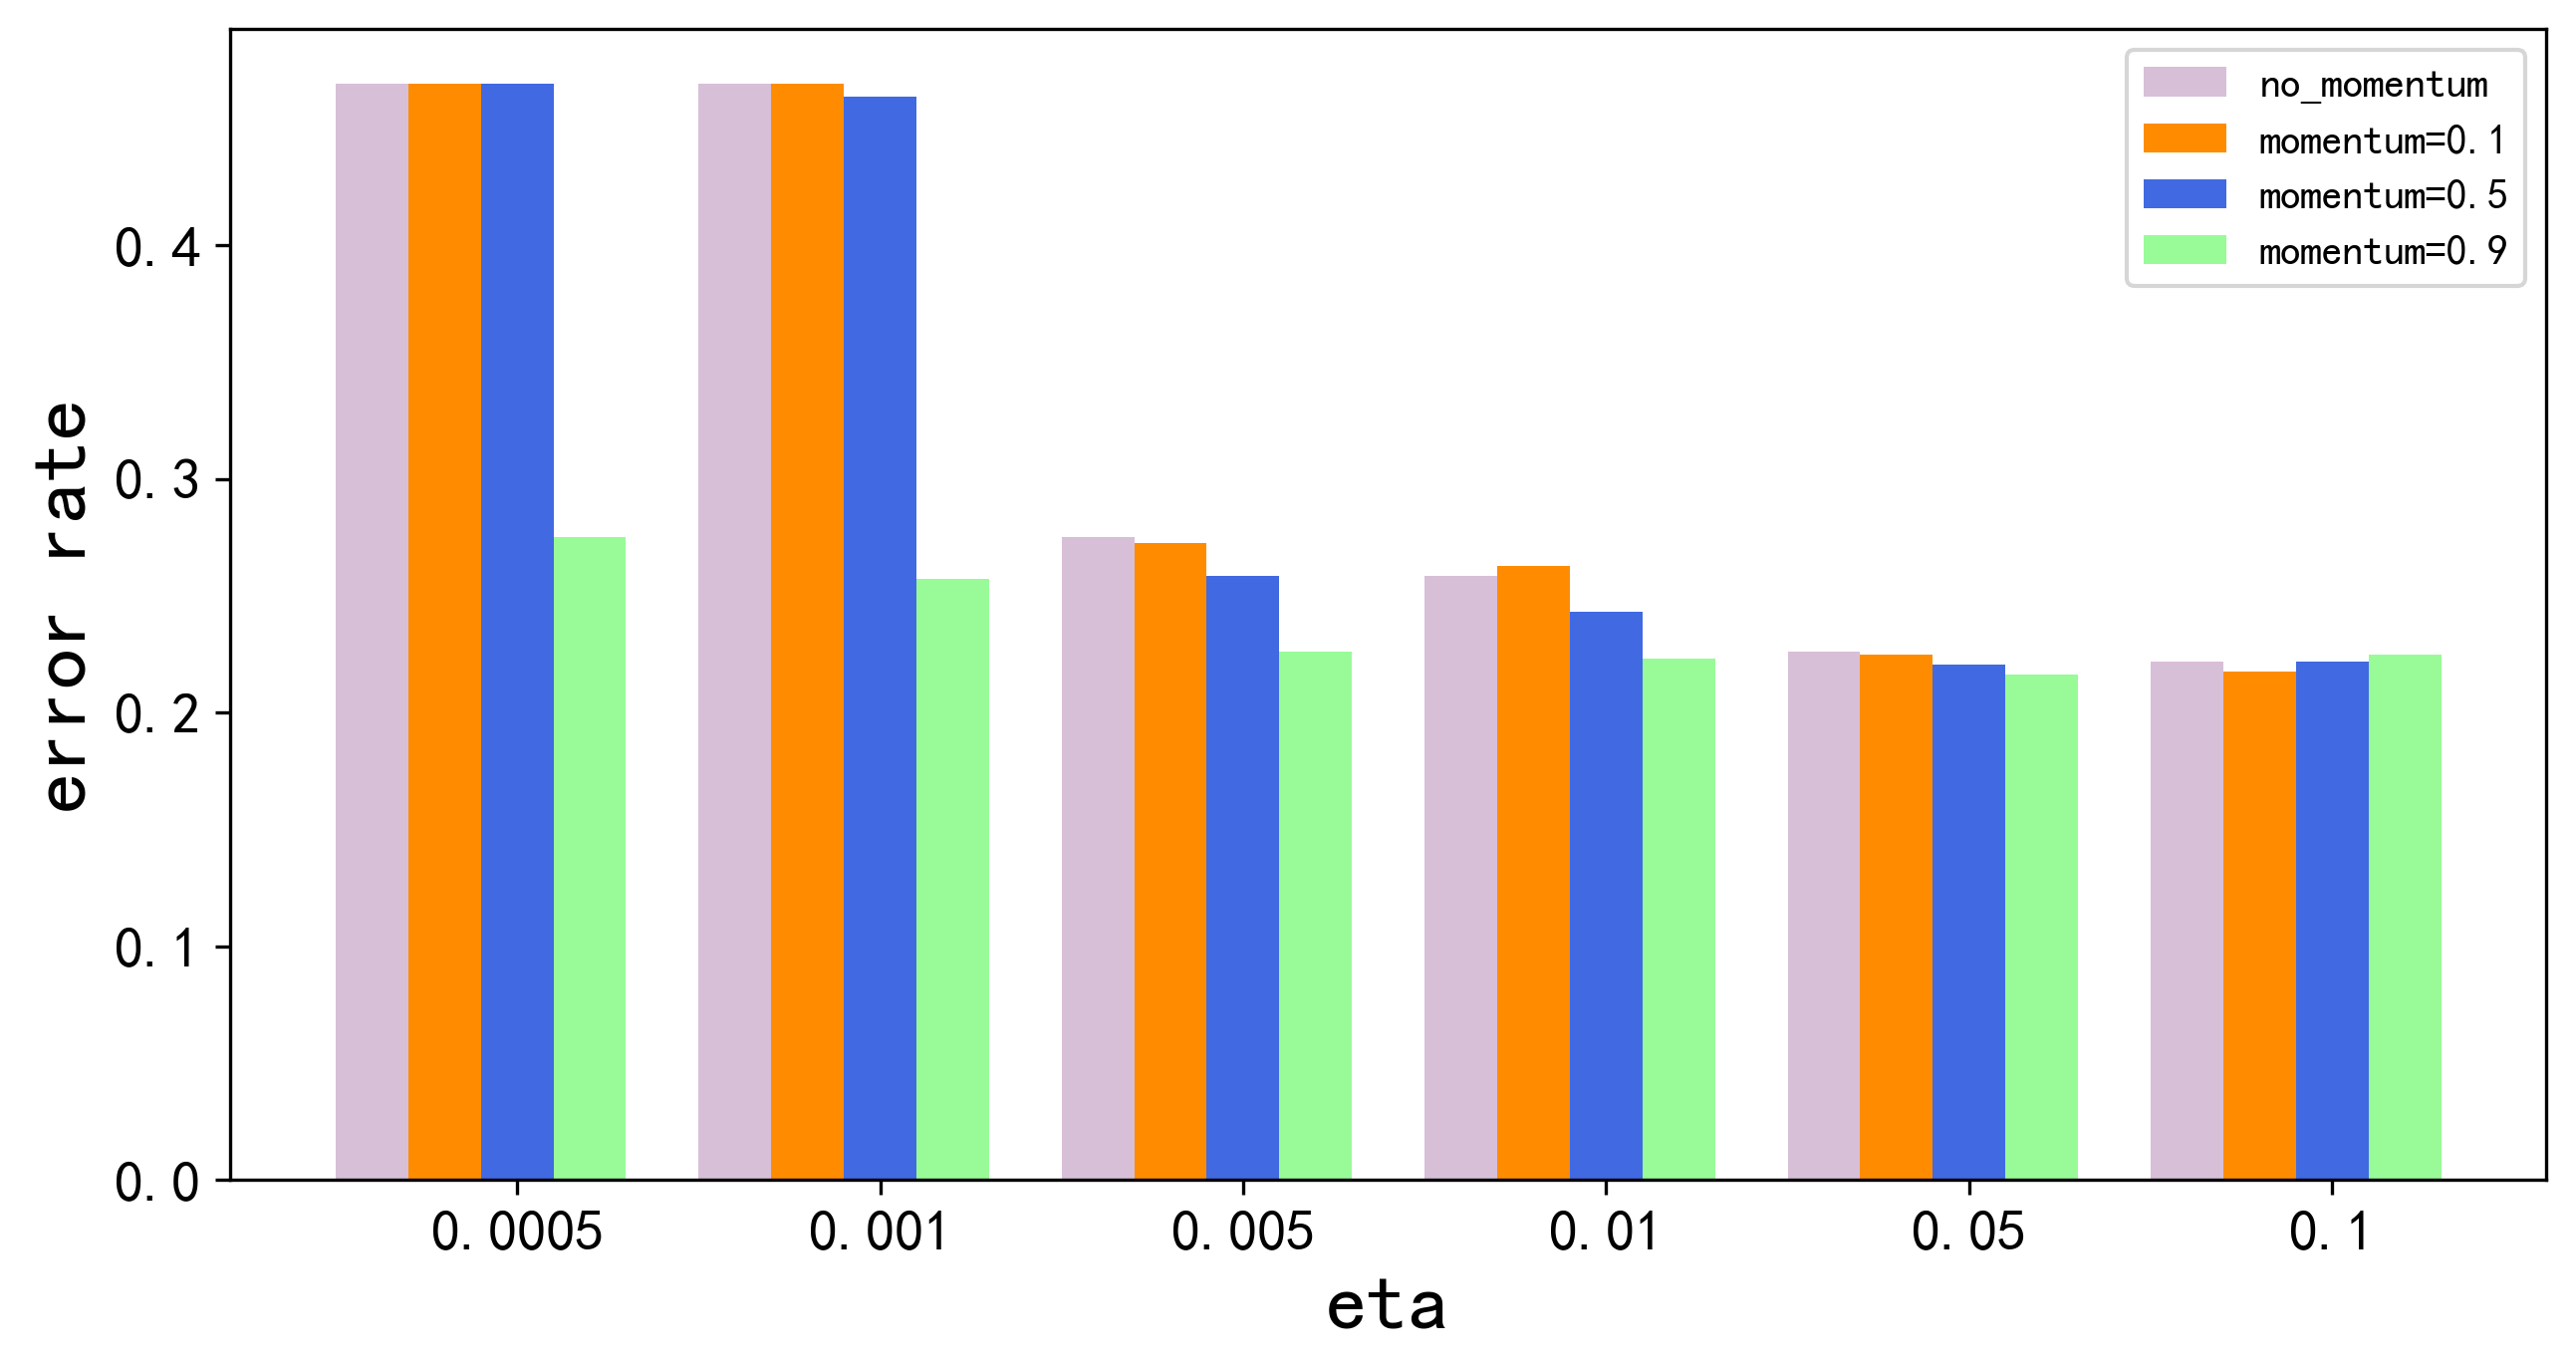

In [17]:
no_momentum = exec_result.query('use_momentum==False')
momentum_01 = exec_result.query('momentum==0.1')
momentum_05 = exec_result.query('momentum==0.5')
momentum_09 = exec_result.query('momentum==0.9')
plt.figure(figsize=(10,5), dpi=300)
plt.rcParams['font.sans-serif']=['SimHei']

plt.bar(np.array(range(0,len(no_momentum['eta'])))+0.6, no_momentum['best_errors_val'].values.tolist()[::-1], width=0.2, color='thistle', label='no_momentum')
plt.bar(np.array(range(0,len(no_momentum['eta'])))+0.8, momentum_01['best_errors_val'].values.tolist()[::-1], width=0.2, color='darkorange', label='momentum=0.1')
plt.bar(np.array(range(0,len(no_momentum['eta'])))+1.0, momentum_05['best_errors_val'].values.tolist()[::-1], width=0.2, color='royalblue', label='momentum=0.5')
plt.bar(np.array(range(0,len(no_momentum['eta'])))+1.2, momentum_09['best_errors_val'].values.tolist()[::-1], width=0.2, color='palegreen', label='momentum=0.9')

plt.xlabel('eta', fontsize=20, fontweight='bold')
plt.ylabel('error rate', fontsize=20, fontweight='bold')
plt.xticks([1,2,3,4,5,6],[0.0005, 0.001, 0.005, 0.01, 0.05, 0.1], fontsize=14)
plt.yticks(fontsize=14)
plt.legend()
plt.show()

In [18]:
no_momentum['best_errors_val'].values.tolist()[::-1]

[0.4691011235955056,
 0.4691011235955056,
 0.2752808988764045,
 0.25842696629213485,
 0.22612359550561797,
 0.22191011235955055]

### 最佳模型

In [74]:
# 取最佳模型
best_index = exec_result['best_errors_val'].idxmin()  
best_result = exec_result.iloc[0]
best_result

model                                                       word2vec
epochs                                                            12
eta                                                              0.1
use_momentum                                                    True
momentum                                                         0.1
best_epoch                                                         9
best_errors_val                                             0.217697
best_weights       [-0.6261195220625236, 0.9604363205614639, -1.1...
losses_train       [0.8439282664202804, 0.6684532487271521, 0.602...
losses_val         [0.8125660574344085, 0.6931751206071112, 0.624...
errors_train       [0.41932457786116323, 0.29924953095684803, 0.2...
errors_val         [0.4452247191011236, 0.31320224719101125, 0.26...
Name: 0, dtype: object

### loss和error rate可视化

In [20]:
def visualization(losses_train, losses_val, errors_train, errors_val):
    plt.figure(figsize=(14,5), dpi=150)
    plt.rcParams['font.sans-serif']=['SimHei']
    plt.subplot(121)
    plt.plot(range(1,len(losses_train)+1), losses_train, marker='s', label='train')
    plt.plot(range(1,len(losses_val)+1), losses_val, marker='s', label='val')
    plt.xlabel('epoch', fontsize=18, fontweight='bold')
    plt.ylabel('loss', fontsize=18, fontweight='bold')
    plt.xticks(range(2,len(errors_train)+1,2), fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend()
    plt.subplot(122)
    plt.plot(range(1,len(errors_train)+1), errors_train, marker='s', label='train')
    plt.plot(range(1,len(errors_val)+1), errors_val, marker='s', label='val')
    plt.xlabel('epoch', fontsize=20, fontweight='bold')
    plt.ylabel('error rate', fontsize=20, fontweight='bold')
    plt.xticks(range(2,len(errors_train)+1,2), fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend()
    plt.show()

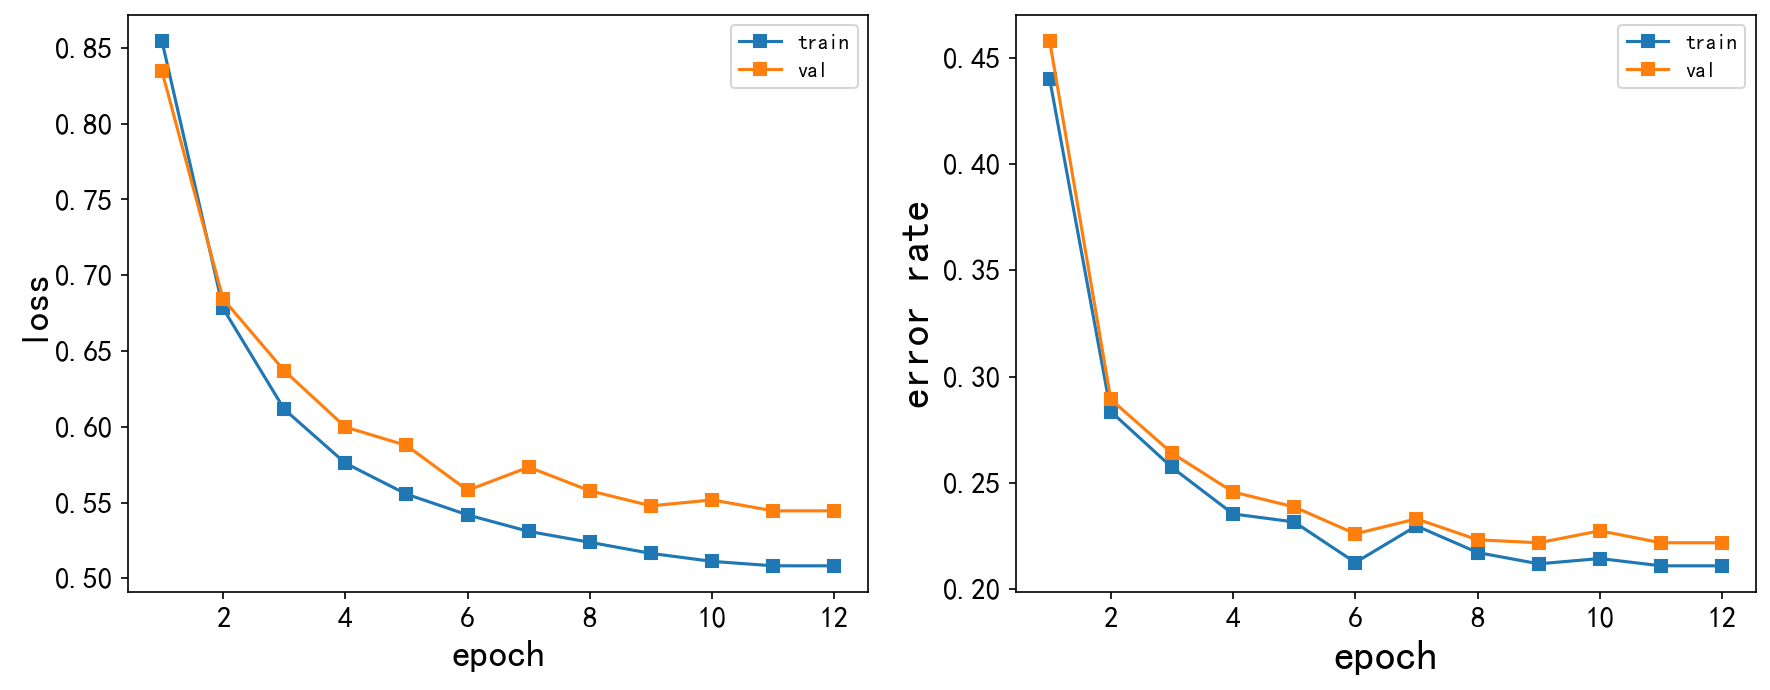

In [53]:
visualization(best_result.losses_train, 
              best_result.losses_val,
              best_result.errors_train,
              best_result.errors_val)

### 测试模型

In [1]:
# 取验证集上最好结果的权重来测试
weights = best_result.best_weights
trainError = evaluatePredictor(trainExamples, 
                               lambda x : (1 if np.dot(featureExtractor(x), weights) >= 0 else -1))
testError= evaluatePredictor(testExamples, 
                            lambda x : (1 if np.dot(featureExtractor(x), weights) >= 0 else -1))
print ("train error = %4f, validate error = %4f, test error = %4f" % (trainError, best_result.best_errors_val, testError)) 

train error = 0.208881, validate error = 0.217697, test error = 0.236398
